In [114]:
from matplotlib.colors import ListedColormap
from sklearn import  datasets, metrics, tree
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [115]:
data = pd.read_csv(f'bioresponse.csv')
data.head()

,Activity,D1,D2,D3,D4,D5,D6,D7,D8,D9,...,D1767,D1768,D1769,D1770,D1771,D1772,D1773,D1774,D1775,D1776
0,1,0.000000,0.497009,0.10,0.0,0.132956,0.678031,0.273166,0.585445,0.743663,...,0,0,0,0,0,0,0,0,0,0
1,1,0.366667,0.606291,0.05,0.0,0.111209,0.803455,0.106105,0.411754,0.836582,...,1,1,1,1,0,1,0,0,1,0
2,1,0.033300,0.480124,0.00,0.0,0.209791,0.610350,0.356453,0.517720,0.679051,...,0,0,0,0,0,0,0,0,0,0
3,1,0.000000,0.538825,0.00,0.5,0.196344,0.724230,0.235606,0.288764,0.805110,...,0,0,0,0,0,0,0,0,0,0
4,0,0.100000,0.517794,0.00,0.0,0.494734,0.781422,0.154361,0.303809,0.812646,...,0,0,0,0,0,0,0,0,0,0


In [116]:
X = data.drop(columns=['Activity'])
y = data.Activity
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 42)
X, y

(            D1        D2    D3   D4        D5        D6        D7        D8  \
 0     0.000000  0.497009  0.10  0.0  0.132956  0.678031  0.273166  0.585445   
 1     0.366667  0.606291  0.05  0.0  0.111209  0.803455  0.106105  0.411754   
 2     0.033300  0.480124  0.00  0.0  0.209791  0.610350  0.356453  0.517720   
 3     0.000000  0.538825  0.00  0.5  0.196344  0.724230  0.235606  0.288764   
 4     0.100000  0.517794  0.00  0.0  0.494734  0.781422  0.154361  0.303809   
 ...        ...       ...   ...  ...       ...       ...       ...       ...   
 3746  0.033300  0.506409  0.10  0.0  0.209887  0.633426  0.297659  0.376124   
 3747  0.133333  0.651023  0.15  0.0  0.151154  0.766505  0.170876  0.404546   
 3748  0.200000  0.520564  0.00  0.0  0.179949  0.768785  0.177341  0.471179   
 3749  0.100000  0.765646  0.00  0.0  0.536954  0.634936  0.342713  0.447162   
 3750  0.133333  0.533952  0.00  0.0  0.347966  0.757971  0.230667  0.272652   
 
             D9       D10  ...  D1767 

In [117]:
small_decision_tree = tree.DecisionTreeClassifier(random_state = 42, max_depth = 2)
small_decision_tree.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,2
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [118]:
predictions = small_decision_tree.predict(X_test)
proba = small_decision_tree.predict_proba(X_test)[:, 1] #log-loss требует вероятность принадлежности к классу, а не просто метки
print('Accuracy - ', metrics.accuracy_score(y_test, predictions))
print('Precision - ', metrics.precision_score(y_test, predictions))
print('Recall - ', metrics.recall_score(y_test, predictions))
print('F1-score - ', metrics.f1_score(y_test, predictions))
print('log-loss - ', metrics.log_loss(y_test, proba))
print(proba)

Accuracy -  0.755863539445629
Precision -  0.7908745247148289
Recall -  0.7775700934579439
F1-score -  0.7841658812441094
log-loss -  0.5335329420058418
[0.79655712 0.79655712 0.21624174 0.79655712 0.21624174 0.79655712
 0.21624174 0.79655712 0.49710983 0.21624174 0.54785479 0.79655712
 0.21624174 0.79655712 0.79655712 0.21624174 0.21624174 0.79655712
 0.79655712 0.79655712 0.79655712 0.49710983 0.54785479 0.21624174
 0.79655712 0.79655712 0.21624174 0.79655712 0.79655712 0.21624174
 0.21624174 0.49710983 0.21624174 0.21624174 0.21624174 0.79655712
 0.21624174 0.79655712 0.21624174 0.49710983 0.79655712 0.79655712
 0.79655712 0.54785479 0.54785479 0.21624174 0.79655712 0.21624174
 0.54785479 0.79655712 0.21624174 0.21624174 0.79655712 0.49710983
 0.54785479 0.21624174 0.79655712 0.79655712 0.79655712 0.21624174
 0.21624174 0.21624174 0.21624174 0.79655712 0.21624174 0.79655712
 0.79655712 0.79655712 0.79655712 0.21624174 0.79655712 0.21624174
 0.79655712 0.79655712 0.79655712 0.7965571

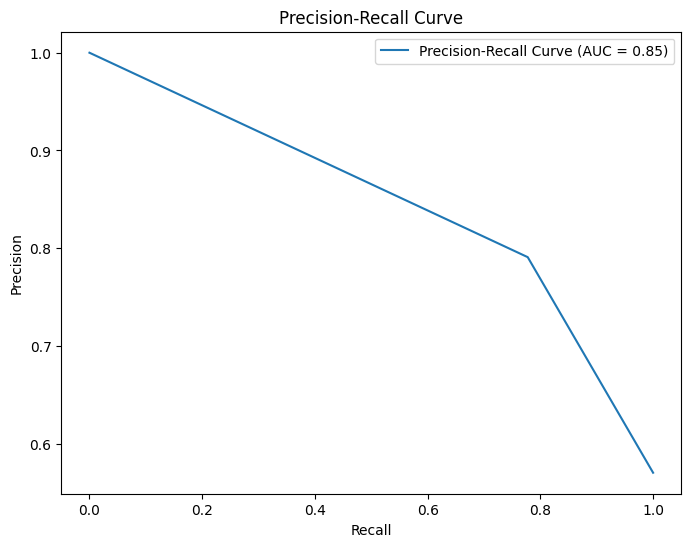

In [119]:
precision, recall, thresholds = metrics.precision_recall_curve(y_test, predictions)
auc_score = metrics.auc(recall, precision)
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, label=f'Precision-Recall Curve (AUC = {auc_score:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.show()

In [120]:
deep_decision_tree = tree.DecisionTreeClassifier(random_state = 42, max_depth = 20)
deep_decision_tree.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,20
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [121]:
predictions = deep_decision_tree.predict(X_test)
proba = deep_decision_tree.predict_proba(X_test)[:, 1]
print('Accuracy - ', metrics.accuracy_score(y_test, predictions))
print('Precision - ', metrics.precision_score(y_test, predictions))
print('Recall - ', metrics.recall_score(y_test, predictions))
print('F1-score - ', metrics.f1_score(y_test, predictions))
print('log-loss - ', metrics.log_loss(y_test, proba)) #Я сначала подумал, что снова неправильно подсчитал, потом прочитал, что это из-за штрафа за слишком уверенные предсказания,
# при такой глубине дерева predict_proba выдает значения 0 или 1(максимально приближенное к ним)
print(proba)

Accuracy -  0.7110874200426439
Precision -  0.7519083969465649
Recall -  0.7364485981308411
F1-score -  0.7440982058545798
log-loss -  9.419967354892792
[0.98601399 1.         0.         0.98601399 0.         1.
 0.         0.99570815 0.         0.         0.         0.98601399
 0.         0.         1.         0.         0.         0.925
 0.925      1.         0.89915966 1.         1.         0.
 0.99570815 0.89915966 0.         1.         1.         1.
 1.         0.         1.         0.         1.         1.
 0.         0.         0.         1.         0.99570815 0.89915966
 0.925      1.         0.         0.         1.         0.
 0.         0.         1.         1.         1.         0.
 1.         0.         1.         1.         1.         1.
 0.         0.         0.         0.         0.         0.89915966
 0.         0.99570815 1.         0.         1.         0.
 1.         1.         1.         0.58823529 0.         0.
 1.         0.         0.         0.         0.      

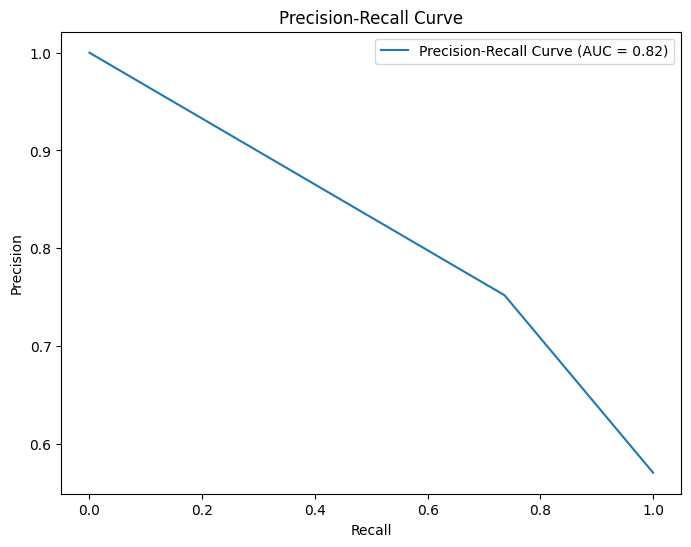

In [122]:
precision, recall, thresholds = metrics.precision_recall_curve(y_test, predictions)
auc_score = metrics.auc(recall, precision)
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, label=f'Precision-Recall Curve (AUC = {auc_score:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.show()

In [123]:
random_forest_small = RandomForestClassifier(n_estimators = 50, max_depth = 2, random_state = 42)
random_forest_small.fit(X_train, y_train)

,n_estimators,50
,criterion,'gini'
,max_depth,2
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [124]:
predictions = random_forest_small.predict(X_test)
proba = random_forest_small.predict_proba(X_test)[:, 1]
print('Accuracy - ', metrics.accuracy_score(y_test, predictions))
print('Precision - ', metrics.precision_score(y_test, predictions))
print('Recall - ', metrics.recall_score(y_test, predictions))
print('F1-score - ', metrics.f1_score(y_test, predictions))
print('log-loss - ', metrics.log_loss(y_test, proba))

Accuracy -  0.720682302771855
Precision -  0.7450628366247756
Recall -  0.7757009345794392
F1-score -  0.76007326007326
log-loss -  0.6175415786717425


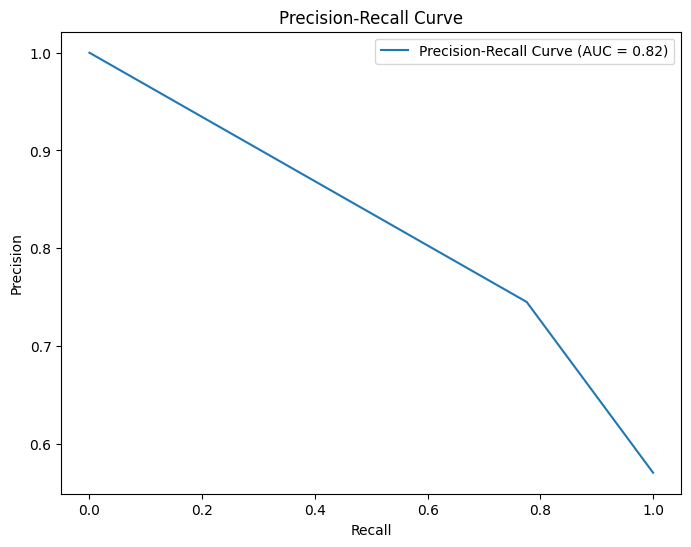

In [125]:
precision, recall, thresholds = metrics.precision_recall_curve(y_test, predictions)
auc_score = metrics.auc(recall, precision)
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, label=f'Precision-Recall Curve (AUC = {auc_score:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.show()

In [126]:
random_forest_deep = RandomForestClassifier(n_estimators = 50, max_depth = 20, random_state = 42)
random_forest_deep.fit(X_train, y_train)

,n_estimators,50
,criterion,'gini'
,max_depth,20
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [127]:
predictions = random_forest_deep.predict(X_test)
proba = random_forest_deep.predict_proba(X_test)[:, 1]
print('Accuracy - ', metrics.accuracy_score(y_test, predictions))
print('Precision - ', metrics.precision_score(y_test, predictions))
print('Recall - ', metrics.recall_score(y_test, predictions))
print('F1-score - ', metrics.f1_score(y_test, predictions))
print('log-loss - ', metrics.log_loss(y_test, proba)) #Здесь и в следующем пункте log-loss имеет нормальное значение, т.к random forest усреднят значения по всем деревьям(в данном случае по 50 деревьям)
print(proba)

Accuracy -  0.8070362473347548
Precision -  0.8314606741573034
Recall -  0.8299065420560747
F1-score -  0.8306828811973808
log-loss -  0.46672387639862506
[0.84       0.98       0.04608394 0.78093122 0.04448694 0.98
 0.37093324 0.81459093 0.32       0.22262736 0.20170317 0.99895804
 0.38490414 0.45373121 0.75783333 0.29797772 0.20140351 0.71905648
 0.66684816 0.90240286 0.86896344 0.53333333 0.44       0.36
 0.93893617 0.89265412 0.12225    0.9560319  0.90887816 0.54
 0.37991891 0.36       0.43873023 0.44191371 0.73947368 0.578255
 0.03232484 0.92       0.45346667 0.66       0.43635078 0.81633303
 0.69411146 0.71566667 0.7        0.14256856 0.87763896 0.23565574
 0.52       0.65859134 0.619375   0.34889138 0.77601178 0.22
 0.5959596  0.14985967 0.56288    0.98       0.93671044 0.40184852
 0.00101351 0.10805724 0.48159638 0.64       0.12666438 0.8923049
 0.53415187 0.97701024 0.85654106 0.58       0.481659   0.42
 0.56960974 0.75320295 0.9        0.71809093 0.45365351 0.16250389
 0.62  

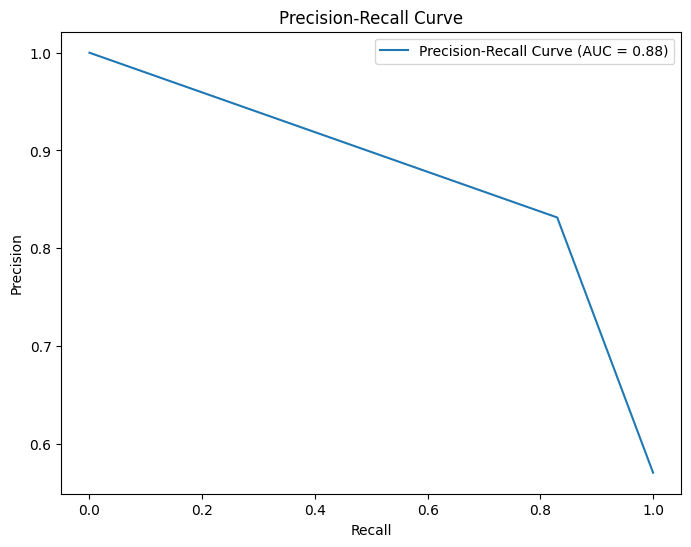

In [128]:
precision, recall, thresholds = metrics.precision_recall_curve(y_test, predictions)
auc_score = metrics.auc(recall, precision)
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, label=f'Precision-Recall Curve (AUC = {auc_score:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.show()

In [129]:
avoid_FN = RandomForestClassifier(n_estimators = 50, max_depth = 20, random_state = 42, class_weight='balanced', bootstrap=True)
avoid_FN.fit(X_train, y_train)

predicted_proba = avoid_FN.predict_proba(X_test)[:, 1]

threshold = 0.3 # С первого раза подгадал, но час читал про threshold
predicted_classes = (predicted_proba >= threshold).astype(int)

In [130]:
print('Accuracy - ', metrics.accuracy_score(y_test, predicted_classes))
print('Precision - ', metrics.precision_score(y_test, predicted_classes))
print('Recall - ', metrics.recall_score(y_test, predicted_classes))
print('F1-score - ', metrics.f1_score(y_test, predicted_classes))
print('log-loss - ', metrics.log_loss(y_test, proba))
print(proba)

Accuracy -  0.7334754797441365
Precision -  0.6912751677852349
Recall -  0.9626168224299065
F1-score -  0.8046875
log-loss -  0.46672387639862506
[0.84       0.98       0.04608394 0.78093122 0.04448694 0.98
 0.37093324 0.81459093 0.32       0.22262736 0.20170317 0.99895804
 0.38490414 0.45373121 0.75783333 0.29797772 0.20140351 0.71905648
 0.66684816 0.90240286 0.86896344 0.53333333 0.44       0.36
 0.93893617 0.89265412 0.12225    0.9560319  0.90887816 0.54
 0.37991891 0.36       0.43873023 0.44191371 0.73947368 0.578255
 0.03232484 0.92       0.45346667 0.66       0.43635078 0.81633303
 0.69411146 0.71566667 0.7        0.14256856 0.87763896 0.23565574
 0.52       0.65859134 0.619375   0.34889138 0.77601178 0.22
 0.5959596  0.14985967 0.56288    0.98       0.93671044 0.40184852
 0.00101351 0.10805724 0.48159638 0.64       0.12666438 0.8923049
 0.53415187 0.97701024 0.85654106 0.58       0.481659   0.42
 0.56960974 0.75320295 0.9        0.71809093 0.45365351 0.16250389
 0.62       0.58

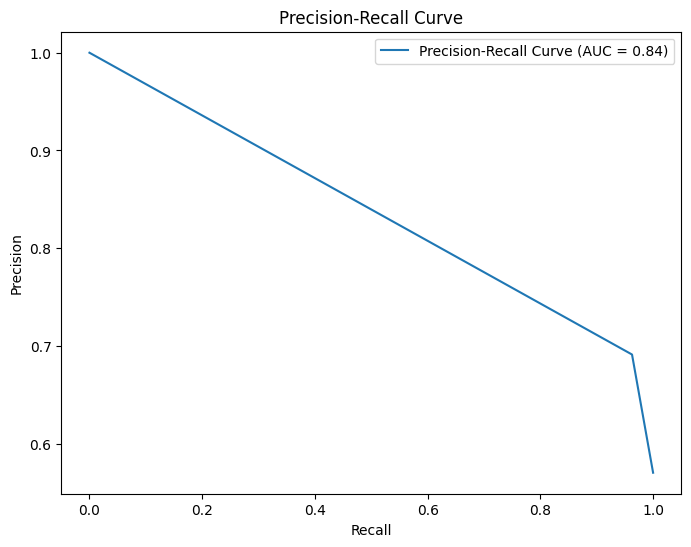

In [131]:
precision, recall, thresholds = metrics.precision_recall_curve(y_test, predicted_classes)
auc_score = metrics.auc(recall, precision)
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, label=f'Precision-Recall Curve (AUC = {auc_score:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.show()

# Вывод
## В деревьях решений в зависимости от глубины дерева, наоборот, AUC значение снизилось (возможно мой подход слишком слабый, я пытался подбирать другую глубину деревьев, эффект везде в районе 80-90)
## В случайном лесу при увеличении глубины деревьев метрики стали лучше, что значит при низкой глубине деревьев происходит недообучение
## Для обучения классификатора избегающий ошибки 2-го рода (FN) надо регулировать значение threshold (это пороговая величина для принятия решения, по умолчанию она 0.5, что необходимо для баланса между precision и recall, при увеличении threshold повышается значение Precision, для ошибок 1-го рода(FP), при уменьшении threshold повышается Recall, что нам и необходимо)